In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/PRJEB38175")
initial_meta<-read.csv("SraRunTable.csv",header = T)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,Bytes,Center.Name,Collection_Date,common_name,⋯,project_name,ReleaseDate,create_date,version,Sample.Name,sample_name,scientific_name,Sequencing_method,SRA.Study,Submitter_Id
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,ERR4100541,AMPLICON,601,32702771,PRJEB38175,SAMEA6816746,21016075,DALHOUSIE UNIVERSITY,2009-01-01/2015-01-01,human,⋯,Assessing the variation within the oral microbiome of healthy adults,2020-05-12T00:00:00Z,2020-05-13T00:12:00Z,1,SAMEA6816746,100000135,Homo sapiens,Illumina,ERP121564,100000135
2,ERR4100542,AMPLICON,601,6772967,PRJEB38175,SAMEA6816720,4390856,DALHOUSIE UNIVERSITY,2009-01-01/2015-01-01,human,⋯,Assessing the variation within the oral microbiome of healthy adults,2020-05-12T00:00:00Z,2020-05-13T00:12:00Z,1,SAMEA6816720,100002335,Homo sapiens,Illumina,ERP121564,100002335
3,ERR4100543,AMPLICON,601,956368,PRJEB38175,SAMEA6816961,705678,DALHOUSIE UNIVERSITY,2009-01-01/2015-01-01,human,⋯,Assessing the variation within the oral microbiome of healthy adults,2020-05-12T00:00:00Z,2020-05-13T00:12:00Z,1,SAMEA6816961,100002535,Homo sapiens,Illumina,ERP121564,100002535
4,ERR4100544,AMPLICON,601,36057426,PRJEB38175,SAMEA6816379,23168469,DALHOUSIE UNIVERSITY,2009-01-01/2015-01-01,human,⋯,Assessing the variation within the oral microbiome of healthy adults,2020-05-12T00:00:00Z,2020-05-13T00:12:00Z,1,SAMEA6816379,100003235,Homo sapiens,Illumina,ERP121564,100003235
5,ERR4100545,AMPLICON,601,26443160,PRJEB38175,SAMEA6817250,17817752,DALHOUSIE UNIVERSITY,2009-01-01/2015-01-01,human,⋯,Assessing the variation within the oral microbiome of healthy adults,2020-05-12T00:00:00Z,2020-05-13T00:12:00Z,1,SAMEA6817250,100004535,Homo sapiens,Illumina,ERP121564,100004535
6,ERR4100546,AMPLICON,601,30069971,PRJEB38175,SAMEA6817254,19338058,DALHOUSIE UNIVERSITY,2009-01-01/2015-01-01,human,⋯,Assessing the variation within the oral microbiome of healthy adults,2020-05-12T00:00:00Z,2020-05-13T00:13:00Z,1,SAMEA6817254,100005135,Homo sapiens,Illumina,ERP121564,100005135


[1] "Run"                                     
 [2] "Assay.Type"                              
 [3] "AvgSpotLen"                              
 [4] "Bases"                                   
 [5] "BioProject"                              
 [6] "BioSample"                               
 [7] "Bytes"                                   
 [8] "Center.Name"                             
 [9] "Collection_Date"                         
[10] "common_name"                             
[11] "Consent"                                 
[12] "DATASTORE.filetype"                      
[13] "DATASTORE.provider"                      
[14] "DATASTORE.region"                        
[15] "ENA.FIRST.PUBLIC..run."                  
[16] "ENA_first_public"                        
[17] "ENA.LAST.UPDATE..run."                   
[18] "ENA_last_update"                         
[19] "environment_.biome."                     
[20] "environment_.feature."                   
[21] "environment_.material."                  
[22] "Experiment"                              
[23] "external_id"                             
[24] "geo_loc_name_country"                    
[25] "geo_loc_name_country_continent"          
[26] "geographic_location_.country_and.or_sea."
[27] "geographic_location_.latitude."          
[28] "geographic_location_.longitude."         
[29] "human_oral_environmental_package"        
[30] "INSDC_center_name"                       
[31] "INSDC_first_public"                      
[32] "INSDC_last_update"                       
[33] "INSDC_status"                            
[34] "Instrument"                              
[35] "Investigation_type"                      
[36] "Library.Name"                            
[37] "LibraryLayout"                           
[38] "LibrarySelection"                        
[39] "LibrarySource"                           
[40] "Organism"                                
[41] "Platform"                                
[42] "project_name"                            
[43] "ReleaseDate"                             
[44] "create_date"                             
[45] "version"                                 
[46] "Sample.Name"                             
[47] "sample_name"                             
[48] "scientific_name"                         
[49] "Sequencing_method"                       
[50] "SRA.Study"                               
[51] "Submitter_Id"

In [3]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = "V4-V5",
    Platform = initial_meta$Platform,
    Country = initial_meta$'geographic_location_.country_and.or_sea.',
    Site = initial_meta$'environment_.material.',
    public_time = initial_meta$ReleaseDate,
    PCR_primers = NA,
    title = 'Assessing the Variation within the Oral Microbiome of Healthy Adults',
    Disease_study = "NO",
    Status = NA,
    matched_samples = 'NO'
)
print(length(unique(uniform_meta$Run)))

print(length(unique(uniform_meta$sample_name)))

[1] 1214
[1] 1214


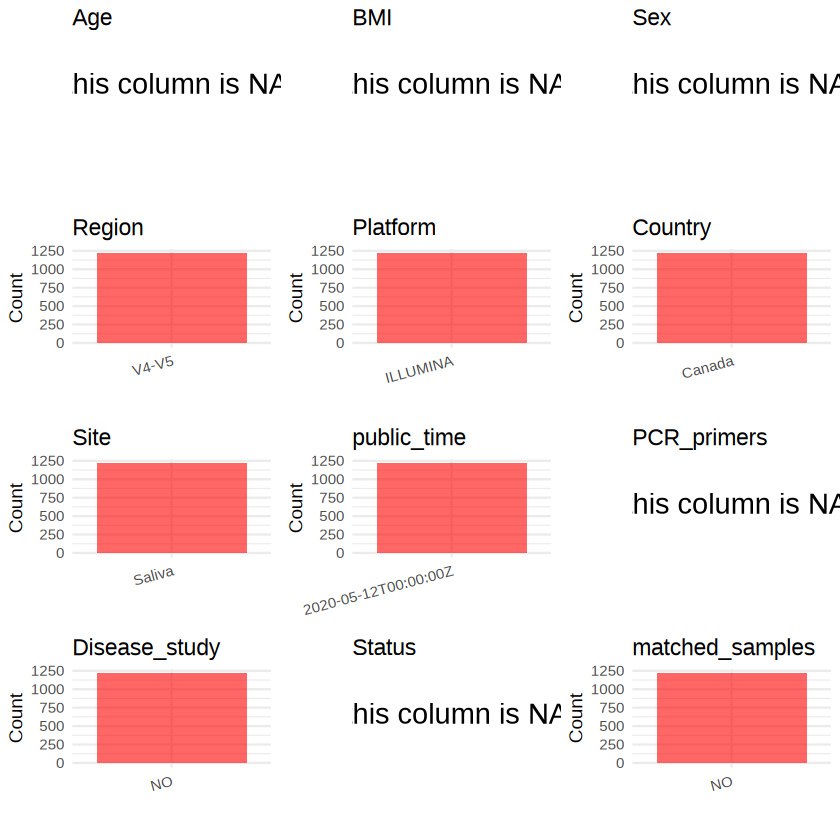

In [4]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)
create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    # Check if the column is all NA
    if (all(is.na(data[[col]]))) {
      # Create an empty plot with text indicating all NA
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      # Numeric variable: histogram
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      # Categorical variable: bar plot (remove NA values)
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  
  return(plots)
}
plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [5]:
## uniform the column order
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/PRJEB38175/uniform_meta.csv", quote = F)